# 12 · Replication in an independent cohort (GSE136831)

Four discovery findings are tested in the Adams *et al.* cohort (28 control,
32 IPF lungs; different centre and 10x 3′ chemistry):

1. **Cell identities transfer**: a classifier trained on our discovery labels
   recovers the authors' independent annotation.
2. **Aberrant basaloid signature** (paired pseudobulk, Notebook 09) identifies
   the authors' aberrant basaloid cells (AUROC).
3. **Composition shifts** (propeller) have the same direction.
4. **Differential expression and pathway activities** replicate: sign
   concordance of discovery DEGs and correlation of PROGENy activities.

Comparing IPF-vs-control *contrasts* (rather than expression levels) between
cohorts cancels chemistry-specific gene biases (3′ vs 5′ capture), because
both groups of a cohort share the same chemistry.

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from adjustText import adjust_text
from matplotlib.patches import Patch
from scipy.stats import binomtest, spearmanr
from sklearn.metrics import adjusted_rand_score, roc_auc_score, roc_curve

from ipfatlas import annotation, composition, enrichment, pseudobulk
from ipfatlas.config import rscript, setup
from ipfatlas.plotting import (
    LINEAGE_COLORS,
    embedding_scatter,
    figsize,
    label_centroids,
    panel_labels,
    save_figure,
    set_style,
)
from ipfatlas.utils import log, timer, write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "12_replication"
TAB = P.tables / "12_replication"
R = rscript(cfg)
D = cfg["de"]
CASE, CTRL = cfg["contrast"]["case"], cfg["contrast"]["control"]

disc = sc.read_h5ad(P.processed / "discovery_annotated.h5ad")
val = sc.read_h5ad(P.processed / "validation_processed.h5ad")
colors = dict(zip(disc.obs["cell_type"].cat.categories, disc.uns["cell_type_colors"]))
ct_comp = disc.obs.groupby("cell_type", observed=True)["compartment"].first().astype(str)
shared = disc.var_names.intersection(val.var_names)
print(f"discovery {disc.n_obs:,} cells | validation {val.n_obs:,} cells | {len(shared):,} shared genes")

discovery 132,455 cells | validation 227,434 cells | 17,644 shared genes


## 1. Label transfer with a CellTypist model trained on the discovery atlas
Logistic regression on log1p(CP10k) expression of shared genes, trained on up
to 2,000 cells per type (balances rare types), with CellTypist's two-pass
feature selection. Predictions are smoothed by majority voting within
over-clusters of the validation kNN graph, at CellTypist's default resolution
for the number of cells (30 above 200,000 cells: several hundred clusters).
The clusters must be much smaller than cell types: at resolution 2 (43
clusters) aberrant basaloid cells, basal cells and pericytes share a cluster
with an abundant neighbour and are outvoted.

In [2]:
rng = np.random.default_rng(0)
idx = np.sort(np.concatenate([rng.choice(np.where(disc.obs["cell_type"] == ct)[0],
                                         min(2000, (disc.obs["cell_type"] == ct).sum()), replace=False)
                              for ct in disc.obs["cell_type"].cat.categories]))
gi = disc.var_names.get_indexer(shared)
tr = ad.AnnData(X=disc.layers["counts"][idx][:, gi].astype(np.float32),
                obs=disc.obs.iloc[idx][["cell_type"]].copy(), var=pd.DataFrame(index=shared))
sc.pp.normalize_total(tr, target_sum=1e4)
sc.pp.log1p(tr)
model_path = P.processed / "models" / "celltypist_discovery.pkl"
with timer("CellTypist training"):
    model = annotation.train_celltypist(tr, labels="cell_type", n_jobs=8, feature_selection=True, top_genes=300,
                                        check_expression=False, max_iter=500)
model.write(str(model_path))
del tr

23:57:26 | INFO | CellTypist training ...


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\celltypist\classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv
🍳 Preparing data before training


✂️ 6 non-expressed genes are filtered out


🔬 Input data has 54026 cells and 17638 genes


⚖️ Scaling input data


🏋️ Training data using SGD logistic regression


... (2 outputs left out)

🏋️ Starting the second round of training


✅ Model training done!


00:37:17 | INFO | CellTypist training done in 2391.0 s


CellTypist training done in 2391.0 s


In [3]:
res = annotation.overclustering_resolution(val.n_obs)
sc.tl.leiden(val, resolution=res, key_added="over_clustering", flavor="igraph", n_iterations=2, random_state=0)
print(f"over-clustering: Leiden resolution {res}, {val.obs['over_clustering'].nunique()} clusters")
with timer("CellTypist prediction"):
    pred = annotation.run_celltypist(val[:, val.var_names.isin(shared)], str(model_path),
                                     over_clustering="over_clustering", layer="counts")
for key, col in [("transferred", "majority_voting"), ("transferred_per_cell", "predicted_labels")]:
    val.obs[key] = pd.Categorical(pred[col].values, categories=[c for c in disc.obs["cell_type"].cat.categories
                                                               if c in set(pred[col])])
val.obs["transferred_conf"] = pred["conf_score"].values
val.obs["transferred_harmonised"] = annotation.harmonise(val.obs["transferred"])
val.obs["compartment"] = val.obs["transferred"].astype(str).map(ct_comp).astype("category")

over-clustering: Leiden resolution 30, 779 clusters
00:37:24 | INFO | CellTypist prediction ...


CellTypist prediction ...


🔬 Input data has 227434 cells and 17644 genes


🔗 Matching reference genes in the model


🧬 3858 features used for prediction


⚖️ Scaling input data


... (2 outputs left out)

🗳️ Majority voting the predictions


✅ Majority voting done!


00:37:39 | INFO | CellTypist prediction done in 14.9 s


CellTypist prediction done in 14.9 s


Agreement with the authors' annotation is measured on the harmonised labels the
model can predict (the discovery atlas has no ILC, PNEC or ionocyte class).
Accuracy and ARI are dominated by the ~140,000 macrophages; the balanced
accuracy (mean recall over cell types) weighs every type equally.

In [4]:
known = set(annotation.harmonise(pd.Series(model.cell_types)).astype(str))
ok = val.obs["harmonised_celltype"].astype(str).isin(known)
truth = val.obs.loc[ok, "harmonised_celltype"].astype(str)
agreement, recall = {}, {}
for name, key in [("majority voting", "transferred"), ("per cell", "transferred_per_cell")]:
    called = annotation.harmonise(val.obs.loc[ok, key]).astype(str)
    recall[name] = (called == truth).groupby(truth).mean()
    agreement[name] = {"ARI": adjusted_rand_score(truth, called), "accuracy": (called == truth).mean(),
                       "balanced_accuracy": recall[name].mean()}
agreement = pd.DataFrame(agreement).T
recall = pd.DataFrame(recall).assign(n_cells=truth.value_counts())
mv = agreement.loc["majority voting"]
log.info(f"label transfer vs Adams annotation: ARI = {mv.ARI:.3f}, accuracy = {mv.accuracy:.3f}, "
         f"balanced accuracy = {mv.balanced_accuracy:.3f}")

conf = pd.crosstab(truth, val.obs.loc[ok, "transferred_harmonised"].astype(str), normalize="index")
order = [c for c in dict.fromkeys(annotation.FINE_TO_HARMONISED.values()) if c in conf.index]
conf = conf.reindex(index=order, columns=[c for c in order if c in conf.columns] +
                    [c for c in conf.columns if c not in order]).fillna(0)
recall = recall.reindex(order)
write_table(conf.round(3), TAB / "label_transfer_confusion")
write_table(recall.round(3), TAB / "label_transfer_recall_per_type")
write_table(agreement.round(3), TAB / "label_transfer_agreement")
agreement.round(3)

00:37:40 | INFO | label transfer vs Adams annotation: ARI = 0.442, accuracy = 0.717, balanced accuracy = 0.842


label transfer vs Adams annotation: ARI = 0.442, accuracy = 0.717, balanced accuracy = 0.842


,ARI,accuracy,balanced_accuracy
majority voting,0.442,0.717,0.842
per cell,0.342,0.652,0.791


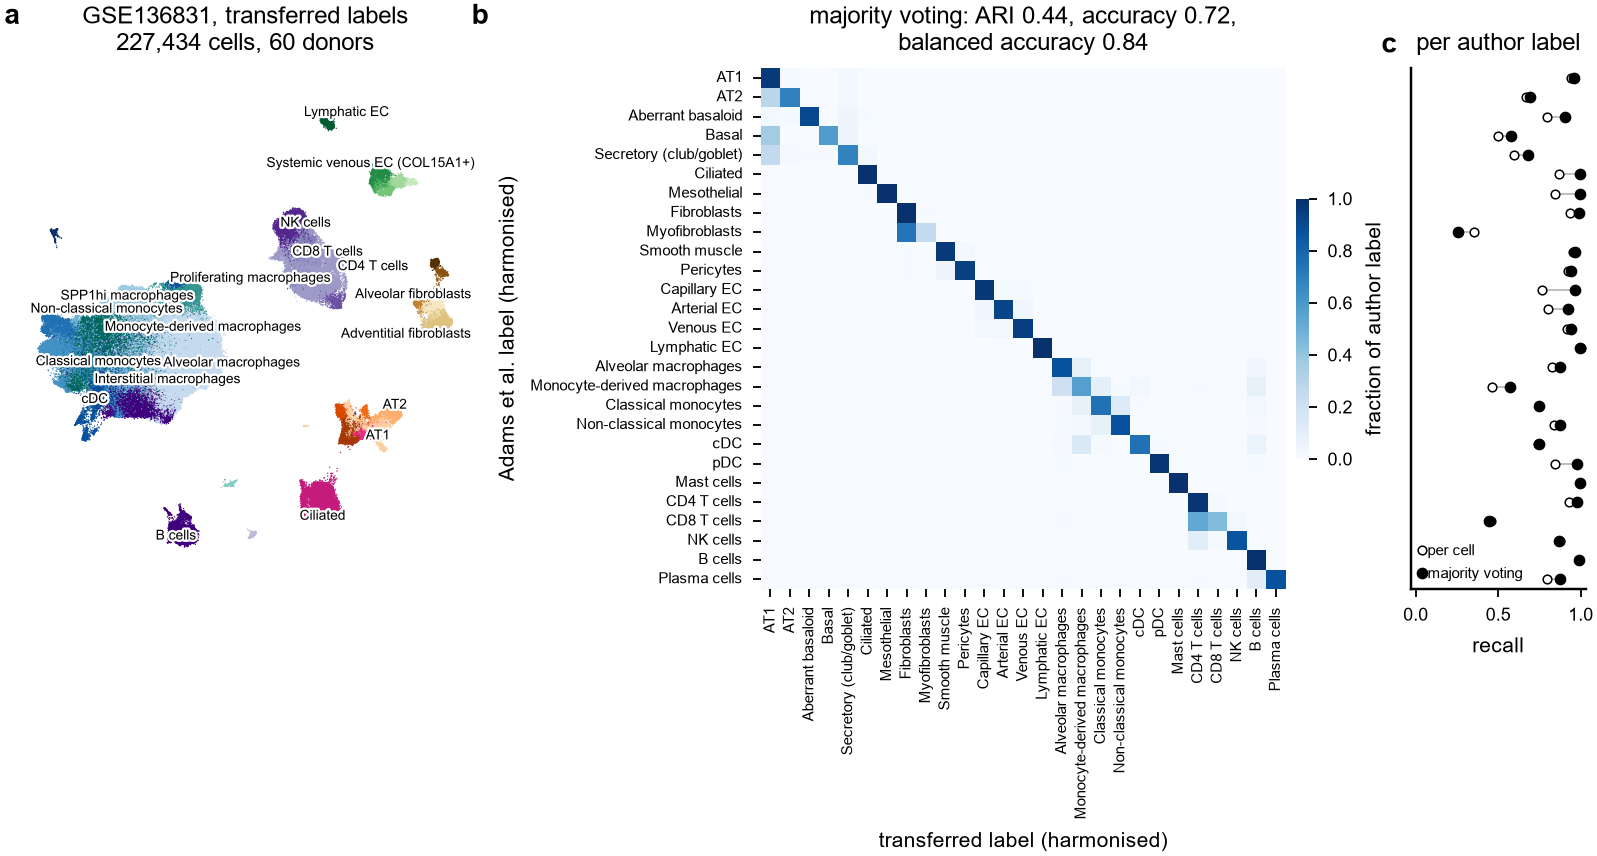

In [5]:
fig = plt.figure(figsize=figsize(183, 100), layout="constrained")
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.2, 0.4])
axes = [fig.add_subplot(gs[0, i]) for i in range(3)]
embedding_scatter(axes[0], val.obsm["X_umap"], val.obs["transferred"], palette=colors, s=0.2)
label_centroids(axes[0], val.obsm["X_umap"], val.obs["transferred"], fontsize=4.5, min_cells=1500)
adjust_text(list(axes[0].texts), ax=axes[0])
axes[0].set_title(f"GSE136831, transferred labels\n{val.n_obs:,} cells, {val.obs.donor_id.nunique()} donors")
sns.heatmap(conf, cmap="Blues", vmin=0, vmax=1, ax=axes[1], xticklabels=True, yticklabels=True,
            cbar_kws={"label": "fraction of author label", "shrink": 0.5, "pad": 0.02})
axes[1].tick_params(labelsize=5)
axes[1].set_xlabel("transferred label (harmonised)")
axes[1].set_ylabel("Adams et al. label (harmonised)")
axes[1].set_title(f"majority voting: ARI {mv.ARI:.2f}, accuracy {mv.accuracy:.2f},\n"
                  f"balanced accuracy {mv.balanced_accuracy:.2f}")
y = np.arange(len(recall)) + 0.5
axes[2].hlines(y, recall["per cell"], recall["majority voting"], color="#BBBBBB", lw=0.6)
axes[2].scatter(recall["per cell"], y, s=8, facecolor="white", edgecolor="black", lw=0.5, zorder=3, label="per cell")
axes[2].scatter(recall["majority voting"], y, s=8, color="black", zorder=3, label="majority voting")
axes[2].set_ylim(len(recall), 0)
axes[2].set_yticks([])
axes[2].set_xlim(-0.03, 1.03)
axes[2].set_xlabel("recall")
axes[2].legend(fontsize=5, loc="lower left", frameon=False, handletextpad=0.1)
axes[2].set_title("per author label")
panel_labels(fig, axes, "abc")
save_figure(fig, "Fig6_label_transfer", FIG)
plt.show()

Majority voting recovers the authors' labels with a balanced accuracy of 0.84
(0.79 cell by cell), and aberrant basaloid cells with a recall of 0.91. The
misses are mostly between neighbouring states that the two annotations split
differently: three quarters of the authors' myofibroblasts are called
fibroblasts, half of their CD8 T cells CD4 T cells, and 26–36 % of their AT2,
basal and secretory cells AT1 cells.

## 2. Aberrant basaloid signature in the validation cohort
Score = mean expression of the 50-gene paired-pseudobulk signature minus a
matched random control set (Tirosh method), among the authors' epithelial
cells. AUROC: how well the score separates the authors' aberrant basaloid
cells from all other epithelial cells. KRT17 alone is the single-gene baseline.

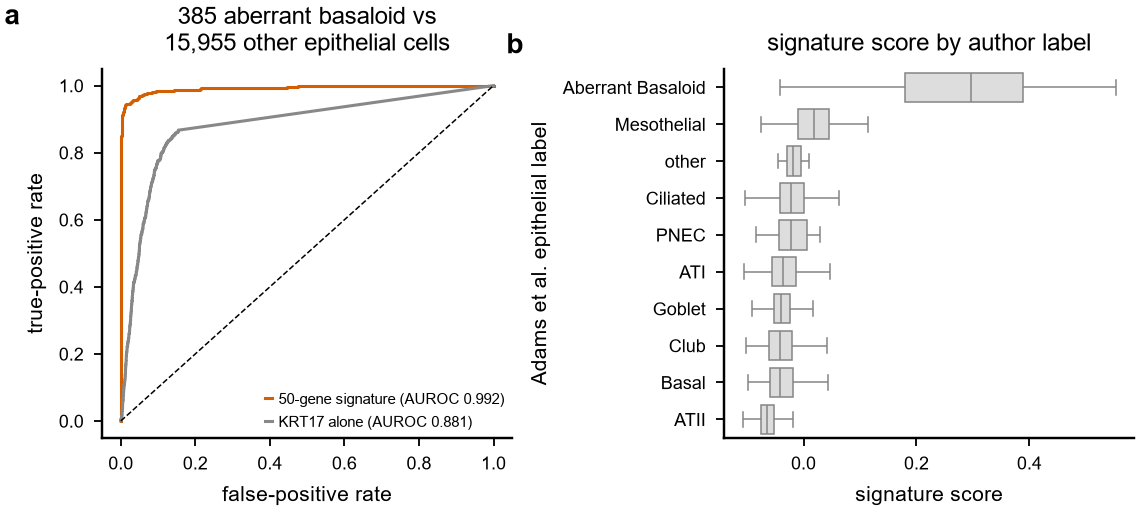

{'50-gene signature': 0.9918768289059734, 'KRT17 alone': 0.8812914568978498}

In [6]:
sig = pd.read_csv(P.tables / "09_trajectory" / "aberrant_basaloid_signature.csv")["gene"]
sig = [g for g in sig if g in val.var_names]
epi = val[val.obs["author_compartment"].astype(str).str.contains("Epithelial", case=False)].copy()
sc.tl.score_genes(epi, sig, score_name="basaloid_sig", random_state=0, use_raw=False)
y = (epi.obs["author_celltype"] == "Aberrant_Basaloid").to_numpy()
scores = {"50-gene signature": epi.obs["basaloid_sig"].to_numpy(),
          "KRT17 alone": np.asarray(epi[:, "KRT17"].X.todense()).ravel()}
auc = {k: roc_auc_score(y, v) for k, v in scores.items()}
write_table(pd.Series(auc, name="AUROC").to_frame().round(4), TAB / "basaloid_signature_auroc")
write_table(pd.DataFrame({"author_celltype": epi.obs["author_celltype"].astype(str).to_numpy(),
                          "signature_score": scores["50-gene signature"].round(4),
                          "KRT17": scores["KRT17 alone"].round(4)}),
            TAB / "basaloid_signature_scores_epithelial", index=False)

fig, axes = plt.subplots(1, 2, figsize=figsize(130, 60), layout="constrained")
for (k, v), col in zip(scores.items(), [LINEAGE_COLORS["Aberrant basaloid"], "#888888"]):
    fpr, tpr, _ = roc_curve(y, v)
    axes[0].plot(fpr, tpr, color=col, lw=1, label=f"{k} (AUROC {auc[k]:.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", lw=0.5, color="black")
axes[0].set_xlabel("false-positive rate")
axes[0].set_ylabel("true-positive rate")
axes[0].legend(fontsize=5, loc="lower right", frameon=False)
axes[0].set_title(f"{y.sum():,} aberrant basaloid vs\n{(~y).sum():,} other epithelial cells")
lab = epi.obs["author_celltype"].astype(str).str.replace("_", " ")
top = lab.value_counts().index[:9]
d = pd.DataFrame({"label": lab.where(lab.isin(top), "other"), "score": epi.obs["basaloid_sig"]})
ordr = d.groupby("label")["score"].median().sort_values(ascending=False).index
sns.boxplot(d, x="score", y="label", order=ordr, ax=axes[1], fliersize=0, linewidth=0.5, color="#DDDDDD")
axes[1].set_xlabel("signature score")
axes[1].set_ylabel("Adams et al. epithelial label")
axes[1].set_title("signature score by author label")
panel_labels(fig, axes, "ab")
save_figure(fig, "Fig6_basaloid_signature_validation", FIG)
plt.show()
auc

The signature, derived only from discovery cells, separates the authors'
385 aberrant basaloid cells from the other 15,955 epithelial cells almost
perfectly (AUROC 0.992); *KRT17*, the defining marker, reaches 0.881 alone.

## 3. Composition replication (propeller, `~ sex + diagnosis`)
Discovery and validation log2 proportion ratios (IPF / control) are compared,
both for all cells and within compartments (the within-compartment view is
robust to differences in tissue dissociation between centres).

00:37:55 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\cells_all.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\propeller_all.csv IPF Control sex


R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\cells_all.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\propeller_all.csv IPF Control sex


00:38:01 | INFO | R finished: propeller.R
25:                     Venous EC   1.7481882 1.652867e-01 2.314014e-01
26:          General capillary EC   0.6265705 2.514805e-01 3.385314e-01
27:       Adventitial fibroblasts   1.5172235 3.186307e-01 4.130398e-01
28:                   CD4 T cells   0.8990593 4.187542e-01 5.234428e-01
29:  Monocyte-derived macrophages   0.9059128 4.432593e-01 5.349681e-01
30:      Interstitial macrophages   0.8025521 4.975680e-01 5.671209e-01
31:                      NK cells   1.1649319 5.023071e-01 5.671209e-01
32:          Alveolar macrophages   0.8789491 7.367393e-01 8.058086e-01
33:                           AT1   0.3650505 8.145636e-01 8.639311e-01
34:                   Arterial EC   0.8516362 9.882915e-01 9.994836e-01
35:         Aerocyte capillary EC   0.5484079 9.994836e-01 9.994836e-01
                         celltype   PropRatio      P.Value          FDR
                           <char>       <num>        <num>        <num>

Performing logit tran

R finished: propeller.R
25:                     Venous EC   1.7481882 1.652867e-01 2.314014e-01
26:          General capillary EC   0.6265705 2.514805e-01 3.385314e-01
27:       Adventitial fibroblasts   1.5172235 3.186307e-01 4.130398e-01
28:                   CD4 T cells   0.8990593 4.187542e-01 5.234428e-01
29:  Monocyte-derived macrophages   0.9059128 4.432593e-01 5.349681e-01
30:      Interstitial macrophages   0.8025521 4.975680e-01 5.671209e-01
31:                      NK cells   1.1649319 5.023071e-01 5.671209e-01
32:          Alveolar macrophages   0.8789491 7.367393e-01 8.058086e-01
33:                           AT1   0.3650505 8.145636e-01 8.639311e-01
34:                   Arterial EC   0.8516362 9.882915e-01 9.994836e-01
35:         Aerocyte capillary EC   0.5484079 9.994836e-01 9.994836e-01
                         celltype   PropRatio      P.Value          FDR
                           <char>       <num>        <num>        <num>

Performing logit transformation of prop

00:38:02 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\cells_Epithelial.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\propeller_Epithelial.csv IPF Control sex


R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\cells_Epithelial.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\propeller_Epithelial.csv IPF Control sex


... (10 outputs left out)

00:38:22 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\cells_Mesenchymal.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\propeller_Mesenchymal.csv IPF Control sex


R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\propeller.R J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\cells_Mesenchymal.csv J:\Portfolio_projects\Projects\scRNA\data\interim\propeller_validation\propeller_Mesenchymal.csv IPF Control sex


00:38:27 | INFO | R finished: propeller.R
celltype PropRatio      P.Value        FDR
                    <char>     <num>        <num>      <num>
1:          Myofibroblasts 5.6917857 0.0008569419 0.00480423
2: Adventitial fibroblasts 0.6056554 0.0016014098 0.00480423
3:    Alveolar fibroblasts 1.2571677 0.1570749048 0.31414981
4:               Pericytes 2.3506715 0.2185842911 0.32787644
5:           Smooth muscle 1.0911657 0.8765994874 0.99206125
6:             Mesothelial 2.0907331 0.9920612457 0.99206125

Performing logit transformation of proportions


R finished: propeller.R
celltype PropRatio      P.Value        FDR
                    <char>     <num>        <num>      <num>
1:          Myofibroblasts 5.6917857 0.0008569419 0.00480423
2: Adventitial fibroblasts 0.6056554 0.0016014098 0.00480423
3:    Alveolar fibroblasts 1.2571677 0.1570749048 0.31414981
4:               Pericytes 2.3506715 0.2185842911 0.32787644
5:           Smooth muscle 1.0911657 0.8765994874 0.99206125
6:             Mesothelial 2.0907331 0.9920612457 0.99206125

Performing logit transformation of proportions


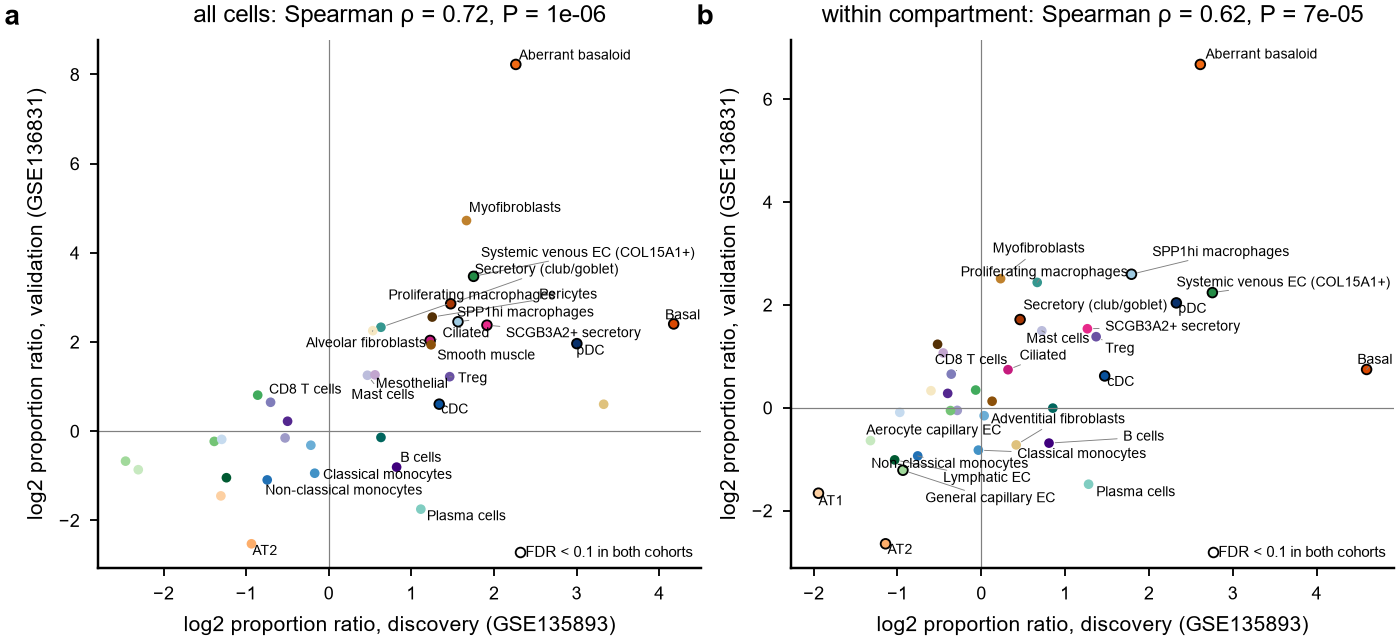

In [7]:
vsub = val[val.obs["transferred"].notna()].copy()
vres = [composition.run_propeller(vsub, R, P.r_scripts / "propeller.R", P.interim / "propeller_validation",
                                  "transferred", "donor_id", "diagnosis", CASE, CTRL, covariates=["sex"],
                                  tag="_all").assign(scope="all cells")]
for comp in ["Epithelial", "Immune", "Endothelial", "Mesenchymal"]:
    s = vsub[vsub.obs["compartment"] == comp].copy()
    s.obs["transferred"] = s.obs["transferred"].cat.remove_unused_categories()
    vres.append(composition.run_propeller(s, R, P.r_scripts / "propeller.R", P.interim / "propeller_validation",
                                          "transferred", "donor_id", "diagnosis", CASE, CTRL, covariates=["sex"],
                                          tag=f"_{comp}").assign(scope=comp))
vres = pd.concat(vres, ignore_index=True)
vres["log2_prop_ratio"] = np.log2(vres["PropRatio"])
dres = pd.read_csv(P.tables / "06_composition" / "propeller_results.csv")
cmp = dres.merge(vres, on=["celltype", "scope"], suffixes=("_disc", "_val"))
write_table(cmp, TAB / "composition_replication", index=False)

fig, axes = plt.subplots(1, 2, figsize=figsize(160, 75), layout="constrained")
for ax, scope_sel, title in [(axes[0], cmp["scope"] == "all cells", "all cells"),
                             (axes[1], cmp["scope"] != "all cells", "within compartment")]:
    d = cmp[scope_sel]
    rho, p = spearmanr(d["log2_prop_ratio_disc"], d["log2_prop_ratio_val"])
    both = (d["FDR_disc"] < 0.1) & (d["FDR_val"] < 0.1)
    ax.axhline(0, lw=0.4, color="grey")
    ax.axvline(0, lw=0.4, color="grey")
    ax.scatter(d["log2_prop_ratio_disc"], d["log2_prop_ratio_val"], s=10,
               c=[colors.get(c, "grey") for c in d["celltype"]], edgecolor=np.where(both, "black", "none"), lw=0.6)
    ax.scatter([], [], s=10, facecolor="white", edgecolor="black", lw=0.6, label="FDR < 0.1 in both cohorts")
    lab = d[(d["FDR_disc"] < 0.1) | (d["FDR_val"] < 0.1)]
    texts = [ax.text(r.log2_prop_ratio_disc, r.log2_prop_ratio_val, r.celltype, fontsize=4.5) for r in lab.itertuples()]
    adjust_text(texts, x=d["log2_prop_ratio_disc"].to_numpy(), y=d["log2_prop_ratio_val"].to_numpy(), ax=ax,
                arrowprops={"arrowstyle": "-", "lw": 0.3, "color": "grey"})
    ax.legend(fontsize=5, loc="lower right", frameon=False, handletextpad=0.1)
    ax.set_xlabel("log2 proportion ratio, discovery (GSE135893)")
    ax.set_ylabel("log2 proportion ratio, validation (GSE136831)")
    ax.set_title(f"{title}: Spearman ρ = {rho:.2f}, P = {p:.1g}")
panel_labels(fig, axes, "ab")
save_figure(fig, "Fig6_composition_replication", FIG)
plt.show()

Composition changes agree between the cohorts (Spearman ρ = 0.72 over all
cells, 0.62 within compartments). All 12 within-compartment changes with
discovery FDR < 0.1 have the same direction in the validation cohort and 10 are
significant there too: the gains of aberrant basaloid, basal, secretory, systemic
venous EC, SPP1<sup>hi</sup> macrophage, cDC and pDC populations and the losses
of AT1, AT2 and general capillary EC. The SCGB3A2⁺ secretory increase and the
aerocyte loss do not reach significance in the validation cohort.

## 4. Differential-expression replication (pseudobulk edgeR, `~ sex + diagnosis`)

In [8]:
pb = pseudobulk.aggregate(vsub, "transferred", "donor_id", "diagnosis", covariates=["sex"],
                          min_cells=D["min_cells_per_pseudobulk"])
vin, vout = P.processed / "pseudobulk" / "validation_in", P.processed / "pseudobulk" / "validation_out"
vindex = pseudobulk.write_inputs(pb, vin, CASE, CTRL, min_donors=D["min_donors_per_group"])
write_table(vindex, TAB / "validation_pseudobulk_samples", index=False)
pseudobulk.run_de(R, P.r_scripts / "pseudobulk_de.R", vin, vout, covariates=["sex"], case=CASE, control=CTRL,
                  methods="edgeR")
ved = pseudobulk.read_results(vout, "edgeR")
write_table(ved, TAB / "validation_edgeR_IPF_vs_control", index=False)
ded = pd.read_csv(P.tables / "07_de" / "edgeR_IPF_vs_control_all_celltypes.csv.gz")

00:39:08 | INFO | R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\pseudobulk_de.R J:\Portfolio_projects\Projects\scRNA\data\processed\pseudobulk\validation_in J:\Portfolio_projects\Projects\scRNA\data\processed\pseudobulk\validation_out sex IPF Control edgeR


R: K:/R_setup/R/R-4.6.1/bin/x64/Rscript.exe --vanilla J:\Portfolio_projects\Projects\scRNA\workflow\R\pseudobulk_de.R J:\Portfolio_projects\Projects\scRNA\data\processed\pseudobulk\validation_in J:\Portfolio_projects\Projects\scRNA\data\processed\pseudobulk\validation_out sex IPF Control edgeR


00:41:42 | INFO | R finished: pseudobulk_de.R
[15/28] Treg                             case=21 control=7 genes=2026
[16/28] NK cells                         case=29 control=20 genes=5012
[17/28] B cells                          case=32 control=28 genes=9568
[18/28] Plasma cells                     case=4 control=8 genes=3423
[19/28] Proliferating macrophages        case=32 control=11 genes=11096
[20/28] Monocyte-derived macrophages     case=32 control=27 genes=11242
[21/28] Aerocyte capillary EC            case=7 control=4 genes=1520
[22/28] General capillary EC             case=12 control=10 genes=1689
[23/28] Arterial EC                      case=14 control=11 genes=1968
[24/28] Venous EC                        case=12 control=5 genes=3757
[25/28] Systemic venous EC (COL15A1+)    case=26 control=4 genes=5794
[26/28] Lymphatic EC                     case=21 control=19 genes=3848
[27/28] Alveolar fibroblasts             case=19 control=8 genes=3394
[28/28] Adventitial fibroblasts      

R finished: pseudobulk_de.R
[15/28] Treg                             case=21 control=7 genes=2026
[16/28] NK cells                         case=29 control=20 genes=5012
[17/28] B cells                          case=32 control=28 genes=9568
[18/28] Plasma cells                     case=4 control=8 genes=3423
[19/28] Proliferating macrophages        case=32 control=11 genes=11096
[20/28] Monocyte-derived macrophages     case=32 control=27 genes=11242
[21/28] Aerocyte capillary EC            case=7 control=4 genes=1520
[22/28] General capillary EC             case=12 control=10 genes=1689
[23/28] Arterial EC                      case=14 control=11 genes=1968
[24/28] Venous EC                        case=12 control=5 genes=3757
[25/28] Systemic venous EC (COL15A1+)    case=26 control=4 genes=5794
[26/28] Lymphatic EC                     case=21 control=19 genes=3848
[27/28] Alveolar fibroblasts             case=19 control=8 genes=3394
[28/28] Adventitial fibroblasts          case=25 contro

00:41:43 | INFO | edgeR: 28 cell types, 182,287 gene tests


edgeR: 28 cell types, 182,287 gene tests


In [9]:
m = ded.merge(ved, on=["celltype", "gene"], suffixes=("_disc", "_val"))
rows = []
for ct, d in m.groupby("celltype"):
    sig = d[d["FDR_disc"] < D["fdr"]]
    if len(sig) < 10:
        continue
    same = (np.sign(sig["logFC_disc"]) == np.sign(sig["logFC_val"])).sum()
    rows.append({"celltype": ct, "n_disc_DEG_tested": len(sig), "sign_concordance": same / len(sig),
                 "binom_P": binomtest(same, len(sig), 0.5, alternative="greater").pvalue,
                 "replicated_FDR05_same_sign": ((sig["FDR_val"] < D["fdr"]) &
                                                (np.sign(sig["logFC_disc"]) == np.sign(sig["logFC_val"]))).mean(),
                 "spearman_logFC_DEGs": spearmanr(sig["logFC_disc"], sig["logFC_val"])[0],
                 "spearman_logFC_all": spearmanr(d["logFC_disc"], d["logFC_val"])[0]})
rep = pd.DataFrame(rows).sort_values("n_disc_DEG_tested", ascending=False)
write_table(rep.round(4), TAB / "de_replication_per_celltype", index=False)
rep.round(3)

,celltype,n_disc_DEG_tested,sign_concordance,binom_P,replicated_FDR05_same_sign,spearman_logFC_DEGs,spearman_logFC_all
8,Monocyte-derived macrophages,319,0.765,0.000,0.386,0.639,0.295
11,Secretory (club/goblet),294,0.571,0.008,0.014,0.149,0.060
1,AT2,250,0.752,0.000,0.056,0.555,0.156
3,Alveolar macrophages,201,0.786,0.000,0.438,0.660,0.204
5,Classical monocytes,136,0.779,0.000,0.456,0.546,0.280
0,AT1,94,0.926,0.000,0.681,0.842,0.552
13,Venous EC,77,0.805,0.000,0.013,0.622,0.283
12,Systemic venous EC (COL15A1+),73,0.753,0.000,0.000,0.581,0.145
14,cDC,67,0.791,0.000,0.343,0.698,0.239
10,SPP1hi macrophages,57,0.860,0.000,0.614,0.828,0.209


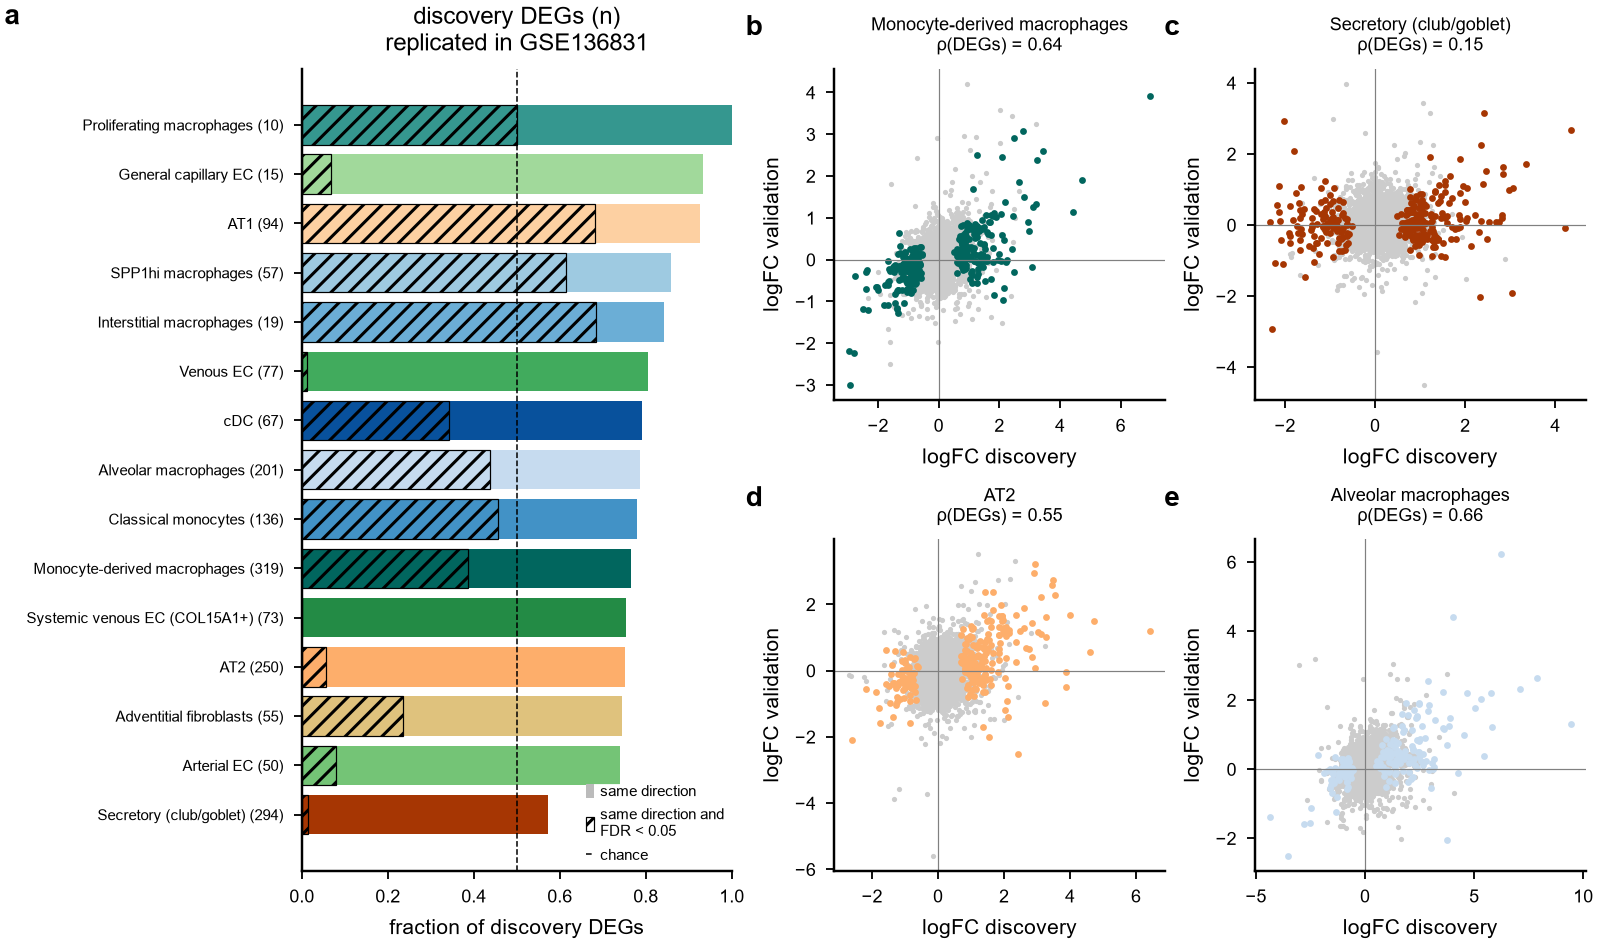

In [10]:
fig = plt.figure(figsize=figsize(183, 110), layout="constrained")
gs = fig.add_gridspec(2, 3, width_ratios=[1.3, 1, 1])
ax = fig.add_subplot(gs[:, 0])
r = rep.sort_values("sign_concordance")
yy = np.arange(len(r))
ax.barh(yy, r["sign_concordance"], color=[colors.get(c, "grey") for c in r["celltype"]])
ax.barh(yy, r["replicated_FDR05_same_sign"], color="none", edgecolor="black", hatch="////", lw=0.4)
ax.axvline(0.5, ls="--", lw=0.5, color="black")
ax.set_yticks(yy, [f"{c} ({n:,})" for c, n in zip(r["celltype"], r["n_disc_DEG_tested"])], fontsize=5)
ax.set_xlim(0, 1)
ax.set_xlabel("fraction of discovery DEGs")
ax.set_title("discovery DEGs (n)\nreplicated in GSE136831")
ax.legend(handles=[Patch(facecolor="#BBBBBB", label="same direction"),
                   Patch(facecolor="white", edgecolor="black", hatch="////", lw=0.4,
                         label="same direction and\nFDR < 0.05"),
                   plt.Line2D([], [], ls="--", lw=0.5, color="black", label="chance")],
          fontsize=5, loc="lower right", frameon=True, framealpha=0.9, edgecolor="none")
axes = [ax]
for i, ct in enumerate(rep["celltype"].head(4)):
    ax2 = fig.add_subplot(gs[i // 2, 1 + i % 2])
    d = m[m["celltype"] == ct]
    s = d["FDR_disc"] < D["fdr"]
    ax2.scatter(d.loc[~s, "logFC_disc"], d.loc[~s, "logFC_val"], s=0.5, color="#CCCCCC", rasterized=True)
    ax2.scatter(d.loc[s, "logFC_disc"], d.loc[s, "logFC_val"], s=1.5, color=colors.get(ct, "black"), rasterized=True)
    ax2.axhline(0, lw=0.4, color="grey")
    ax2.axvline(0, lw=0.4, color="grey")
    ax2.set_title(f"{ct}\nρ(DEGs) = {rep.set_index('celltype').loc[ct, 'spearman_logFC_DEGs']:.2f}", fontsize=6)
    ax2.set_xlabel("logFC discovery")
    ax2.set_ylabel("logFC validation")
    axes.append(ax2)
panel_labels(fig, axes, "abcde")
save_figure(fig, "Fig6_de_replication", FIG)
plt.show()

In all 15 cell types with at least ten testable discovery DEGs, more DEGs keep
their direction than chance allows (sign concordance 0.57–1.00, median 0.79;
one-sided binomial P ≤ 0.008). Far fewer are significant again (0–68 % at
FDR < 0.05): the validation cohort has fewer cells per donor and cell type, and a
discovery effect can be real yet smaller elsewhere. Airway secretory cells, which
had the most discovery DEGs, replicate least (0.57), so part of their signal
belongs to the discovery cohort. Among cell types with more than 50 DEGs, AT1
cells (0.93) and SPP1<sup>hi</sup> macrophages (0.86) replicate best.

## 5. Pathway-activity replication (PROGENy)
PROGENy activities are computed from the validation edgeR statistics exactly
as in Notebook 08. Replication is assessed per pathway, across cell types: does
the pathway change in the same cell types, in the same direction?

In [11]:
progeny = enrichment.resource("progeny", top=500)
p_val, padj_val = enrichment.activity_from_stats(pseudobulk.stat_matrix(ved, "stat"), progeny)
p_disc = pd.read_csv(P.tables / "08_pathways" / "progeny_scores.csv", index_col=0)
padj_disc = pd.read_csv(P.tables / "08_pathways" / "progeny_padj.csv", index_col=0)
common = p_disc.index.intersection(p_val.index)
corr = pd.Series({ct: spearmanr(p_disc.loc[ct], p_val.loc[ct])[0] for ct in common}, name="spearman_rho")
rows = []
for pw in p_disc.columns:
    a, b, sig = p_disc.loc[common, pw], p_val.loc[common, pw], padj_disc.loc[common, pw] < 0.05
    rows.append({"pathway": pw, "spearman_rho_across_celltypes": spearmanr(a, b)[0],
                 "n_celltypes_FDR05_discovery": int(sig.sum()),
                 "sign_agreement_FDR05_discovery": (np.sign(a[sig]) == np.sign(b[sig])).mean() if sig.any() else np.nan,
                 "mean_activity_discovery": a.mean(), "mean_activity_validation": b.mean()})
pw_rep = pd.DataFrame(rows).sort_values("spearman_rho_across_celltypes", ascending=False)
write_table(p_val.round(3), TAB / "validation_progeny_scores")
write_table(corr.round(3).to_frame(), TAB / "progeny_replication_correlation")
write_table(pw_rep.round(3), TAB / "progeny_replication_per_pathway", index=False)
pw_rep.round(2)

,pathway,spearman_rho_across_celltypes,n_celltypes_FDR05_discovery,sign_agreement_FDR05_discovery,mean_activity_discovery,mean_activity_validation
2,Estrogen,0.82,9,0.89,1.61,0.11
8,TGFb,0.54,17,0.94,2.32,0.88
4,JAK-STAT,0.46,13,0.62,2.58,-0.18
10,Trail,0.46,3,0.67,0.20,0.80
7,PI3K,0.27,22,0.45,4.39,-0.54
1,EGFR,0.25,24,0.71,6.02,0.67
13,p53,0.20,13,0.23,-1.87,1.18
3,Hypoxia,0.12,5,1.00,0.02,0.31
9,TNFa,0.08,21,0.29,4.61,-3.70
12,WNT,0.08,1,1.00,-0.37,0.25


The discovery contrast shows strong EGFR, MAPK, NF-κB and TNF-α activation in
almost every cell type, which the validation cohort does not share. Two
explanations are checked: site confounding (Notebook 01), using Notebook 07's
site-adjusted and Vanderbilt-only edgeR results, and the genes that carry the
signal (PROGENy weight × discovery statistic, summed over cell types).

In [12]:
acute = ["EGFR", "MAPK", "NFkB", "TNFa"]
W07 = P.interim / "pseudobulk"
sens = {"discovery, ~ sex + diagnosis": p_disc}
for name, d in [("discovery, ~ site + sex + diagnosis", "site_out"), ("discovery, Vanderbilt only", "vu_out")]:
    sens[name] = enrichment.activity_from_stats(pseudobulk.stat_matrix(pseudobulk.read_results(W07 / d, "edgeR"), "stat"),
                                                progeny)[0]
sens["validation, ~ sex + diagnosis"] = p_val
site_check = pd.DataFrame({k: v.loc[v.index.intersection(common), acute].mean() for k, v in sens.items()}).T
site_check["median_rho_with_validation"] = [
    np.nanmedian([spearmanr(v.loc[ct], p_val.loc[ct])[0] for ct in v.index.intersection(common)]) for v in sens.values()]
write_table(site_check.round(2), TAB / "progeny_site_sensitivity")

stat_d, stat_v = pseudobulk.stat_matrix(ded, "stat"), pseudobulk.stat_matrix(ved, "stat")
rows = []
for pw in ["MAPK", "NFkB", "TNFa"]:
    w = progeny[progeny["source"] == pw].set_index("target")["weight"]
    g = w.index.intersection(stat_d.columns).intersection(stat_v.columns)
    contrib = (stat_d.loc[common, g] * w[g]).sum().sort_values(ascending=False).head(10)
    rows += [{"pathway": pw, "gene": gene, "contribution_discovery": c,
              "median_stat_discovery": stat_d.loc[common, gene].median(),
              "median_stat_validation": stat_v.loc[common, gene].median()} for gene, c in contrib.items()]
drivers = pd.DataFrame(rows)
write_table(drivers.round(2), TAB / "progeny_discordant_drivers", index=False)
site_check.round(2)

00:41:52 | INFO | edgeR: 31 cell types, 195,599 gene tests


edgeR: 31 cell types, 195,599 gene tests


00:41:52 | INFO | edgeR: 29 cell types, 152,536 gene tests


edgeR: 29 cell types, 152,536 gene tests


,EGFR,MAPK,NFkB,TNFa,median_rho_with_validation
"discovery, ~ sex + diagnosis",6.02,5.11,5.43,4.61,-0.09
"discovery, ~ site + sex + diagnosis",6.11,5.40,5.45,4.40,-0.10
"discovery, Vanderbilt only",6.15,5.41,4.99,3.82,-0.11
"validation, ~ sex + diagnosis",0.67,-0.22,-4.58,-3.70,1.00


In [13]:
drivers.round(2)

,pathway,gene,contribution_discovery,median_stat_discovery,median_stat_validation
0,MAPK,DUSP6,960.88,2.41,0.42
1,MAPK,PHLDA1,327.58,1.24,0.46
2,MAPK,CCND1,266.48,0.10,0.00
3,MAPK,IER3,216.20,0.84,0.00
4,MAPK,PNP,208.02,1.59,0.02
5,MAPK,DUSP4,207.33,0.00,0.00
6,MAPK,AREG,176.83,1.04,0.00
7,MAPK,SPRED1,159.41,0.00,0.00
8,MAPK,DUSP5,144.82,0.36,-0.16
9,MAPK,TOP1,139.30,1.47,1.25


**What replicates.** TGF-β, the canonical profibrotic pathway, replicates best
among the pathways that are active in many discovery cell types: its activities
correlate across cell types (ρ = 0.54) and keep their sign in 16 of the 17 cell
types where the discovery activity is significant. Oestrogen (ρ = 0.82) and
JAK-STAT (ρ = 0.46) also replicate, and EGFR keeps its sign in 17 of 24 cell
types.

**What does not.** The strongest discovery signals, NF-κB, TNF-α and MAPK, do
not replicate; NF-κB and TNF-α are on average *lower* in IPF in the validation
cohort. Site does not explain this: adjusting for site or using only the
Vanderbilt donors leaves the discovery activities strongly positive (table
above), and their correlation with the validation activities stays below zero. The
signal is carried by inflammatory chemokines and NF-κB targets (*CCL2*, *CXCL8*,
*ICAM1*, *IL32*, *BIRC3*) and by MAPK feedback and early-response genes
(*DUSP6*, *PHLDA1*, *IER3*). These genes respond within hours to the state of the
lung at procurement, ischaemia time and tissue handling, none of which is
recorded in either cohort. The acute inflammatory programme is therefore
reported as specific to the discovery cohort and not interpreted as part of IPF.

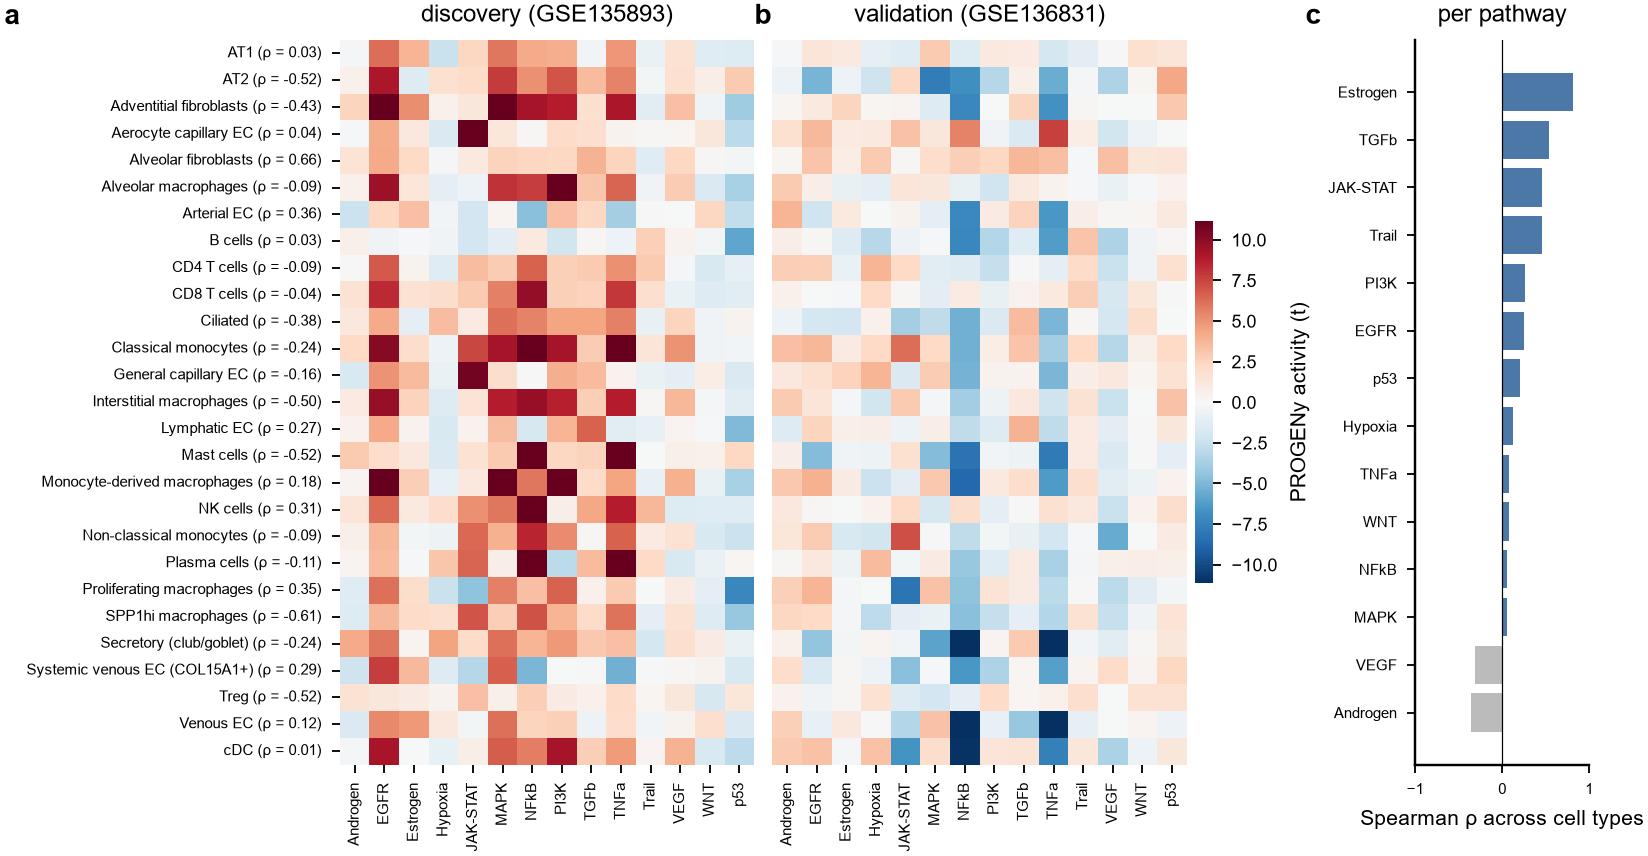

Alveolar fibroblasts             0.66
Arterial EC                      0.36
Proliferating macrophages        0.35
NK cells                         0.31
Systemic venous EC (COL15A1+)    0.29
Lymphatic EC                     0.27
Monocyte-derived macrophages     0.18
Venous EC                        0.12
Aerocyte capillary EC            0.04
AT1                              0.03
B cells                          0.03
cDC                              0.01
CD8 T cells                     -0.04
CD4 T cells                     -0.09
Alveolar macrophages            -0.09
Non-classical monocytes         -0.09
Plasma cells                    -0.11
General capillary EC            -0.16
Classical monocytes             -0.24
Secretory (club/goblet)         -0.24
Ciliated                        -0.38
Adventitial fibroblasts         -0.43
Interstitial macrophages        -0.50
Treg                            -0.52
AT2                             -0.52
Mast cells                      -0.52
SPP1hi macro

In [14]:
fig = plt.figure(figsize=figsize(183, 100), layout="constrained")
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.42])
axes = [fig.add_subplot(gs[0, i]) for i in range(3)]
lim = np.nanpercentile(np.abs(np.r_[p_disc.loc[common].values.ravel(), p_val.loc[common].values.ravel()]), 98)
for ax, mat, t in [(axes[0], p_disc.loc[common], "discovery (GSE135893)"), (axes[1], p_val.loc[common], "validation (GSE136831)")]:
    sns.heatmap(mat, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, ax=ax, cbar=ax is axes[1],
                cbar_kws={"label": "PROGENy activity (t)", "shrink": 0.5, "pad": 0.02},
                xticklabels=True, yticklabels=ax is axes[0])
    ax.set_title(t)
    ax.tick_params(labelsize=5)
axes[0].set_yticks(np.arange(len(common)) + 0.5, [f"{c} (ρ = {corr[c]:.2f})" for c in common], fontsize=5)
r = pw_rep.sort_values("spearman_rho_across_celltypes")
axes[2].barh(r["pathway"], r["spearman_rho_across_celltypes"],
             color=np.where(r["spearman_rho_across_celltypes"] > 0, "#4C78A8", "#BBBBBB"))
axes[2].axvline(0, lw=0.4, color="black")
axes[2].set_xlim(-1, 1)
axes[2].tick_params(labelsize=5)
axes[2].set_xlabel("Spearman ρ across cell types")
axes[2].set_title("per pathway")
panel_labels(fig, axes, "abc")
save_figure(fig, "S12_progeny_replication", FIG)
plt.show()
corr.sort_values(ascending=False).round(2)

## Summary
| finding (discovery) | validation (GSE136831) |
|---|---|
| 36 cell types, incl. aberrant basaloid cells | labels transfer with balanced accuracy 0.84; aberrant basaloid recall 0.91 |
| 50-gene aberrant basaloid signature | finds the authors' aberrant basaloid cells, AUROC 0.992 |
| composition shifts | 10 of 12 within-compartment changes replicate (ρ = 0.62) |
| DEGs in 31 cell types | sign concordance above chance in all 15 testable cell types |
| TGF-β activity | replicates (ρ = 0.54, same sign in 16/17 cell types) |
| NF-κB / TNF-α / MAPK activity | does not replicate; cohort-specific acute programme |

The validation cohort is written with the transferred labels for reuse.

In [15]:
val.write_h5ad(P.processed / "validation_annotated.h5ad", compression="lzf")